## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [3]:
train_model(model, 10)
test_model(model)

Epoch 1/10, Loss: 2.012
Epoch 2/10, Loss: 1.729
Epoch 3/10, Loss: 1.627
Epoch 4/10, Loss: 1.596
Epoch 5/10, Loss: 1.582
Epoch 6/10, Loss: 1.572
Epoch 7/10, Loss: 1.566
Epoch 8/10, Loss: 1.561
Epoch 9/10, Loss: 1.557
Epoch 10/10, Loss: 1.553
Accuracy on images: 92.76


### Write the interval analysis for the simple model

Epoch 1/15, Loss: 2.048
Epoch 2/15, Loss: 1.695
Epoch 3/15, Loss: 1.616
Epoch 4/15, Loss: 1.593
Epoch 5/15, Loss: 1.580
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.551
Epoch 12/15, Loss: 1.548
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.543
Epoch 15/15, Loss: 1.541
Accuracy on images: 93.18


----------------------------------
epsilon:    0.01, count:   7030 / 10000, accuracy:            70.30%
epsilon:    0.02, count:   2410 / 10000, accuracy:            24.10%
epsilon:    0.03, count:    460 / 10000, accuracy:             4.60%
epsilon:    0.04, count:     59 / 10000, accuracy:             0.59%
epsilon:    0.05, count:      2 / 10000, accuracy:             0.02%
epsilon:    0.06, count:      0 / 10000, accuracy:             0.00%
epsilon:    0.07, count:      0 / 10000, accuracy:             0.00%
epsilon:    0.08, count:      0 / 10000, accuracy:             0.00%
epsilon:    0.09, c

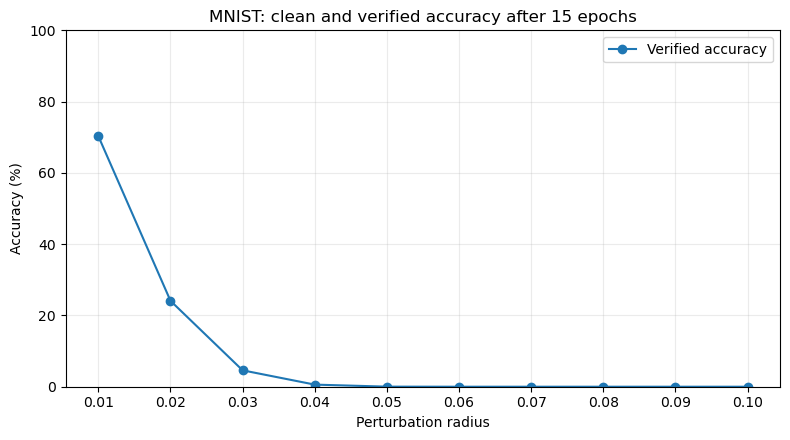

In [4]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()

train_model(model, 15)
test_model(model)

def linear_interval(lower, upper, weight, bias):
    """Bounds for W*x+b: W+*l+W-*u+b, W+*u+W-*l+b."""
    positive = weight.clamp(min=0)
    negative = weight.clamp(max=0)
    lower_out = F.linear(lower, positive, bias) + F.linear(upper, negative)
    upper_out = F.linear(upper, positive, bias) + F.linear(lower, negative)
    return lower_out, upper_out


@torch.no_grad()
def interval_analysis(model, images, labels, epsilon):
    if epsilon < 0:
        raise ValueError("epsilon must be nonnegative")
    net = model[1]

    lower = (images - epsilon).clamp(0, 1)
    upper = (images + epsilon).clamp(0, 1)
    lower = model[0](lower).flatten(1)
    upper = model[0](upper).flatten(1)

    lower, upper = linear_interval(lower, upper, net.fc.weight, net.fc.bias)
    lower, upper = F.relu(lower), F.relu(upper)

    classes = torch.arange(net.fc2.out_features, device=labels.device)
    other = classes.expand(labels.size(0), -1)
    other = other[other != labels[:, None]].reshape(labels.size(0), -1)
    weight = net.fc2.weight[labels, None, :] - net.fc2.weight[other]
    bias = net.fc2.bias[labels, None] - net.fc2.bias[other]
    positive, negative = weight.clamp(min=0), weight.clamp(max=0)
    margin_lower = (positive * lower[:, None, :] + negative * upper[:, None, :]).sum(dim=-1) + bias
    margin_upper = (positive * upper[:, None, :] + negative * lower[:, None, :]).sum(dim=-1) + bias
    return margin_lower, margin_upper

@torch.no_grad()
def evaluate_intervals(model, loader, epsilons):
    model.eval()
    model_device = next(model.parameters()).device
    verified_counts = np.zeros(len(epsilons), dtype=np.int64)
    correct, total, verified_zero = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(model_device), labels.to(model_device)
        clean_correct = model(images).argmax(dim=1).eq(labels)
        correct += clean_correct.sum().item()
        total += labels.size(0)

        zero_lower, _ = interval_analysis(model, images, labels, 0.0)
        verified_zero += ((zero_lower >= 0).all(dim=1)
                          & clean_correct).sum().item()
        previous = clean_correct
        for index, epsilon in enumerate(epsilons):
            lower, upper = interval_analysis(model, images, labels, float(epsilon))
            assert torch.isfinite(lower).all() and torch.isfinite(upper).all()
            assert (lower <= upper + 1e-5).all(), "Invalid interval"
            verified = (lower >= 0).all(dim=1) & clean_correct
            assert not (verified & ~previous).any(), "Certificates must be nested"
            verified_counts[index] += verified.sum().item()
            previous = verified
    assert total == len(loader.dataset), "Evaluate every test image"
    assert verified_zero == correct, "At epsilon=0, bounds must recover clean accuracy"
    return correct, total, verified_counts

model.eval()
epsilons = np.linspace(0.01, 0.10, 10)
start_time = time.time()
_, total, verified_counts = evaluate_intervals(model, test_loader, epsilons)
verified_accuracies = 100.0 * verified_counts / total

print("\n\n----------------------------------")
for epsilon, count, accuracy in zip(epsilons, verified_counts, verified_accuracies):
    print(f"epsilon: {epsilon:7.2f}, count: {count:6d} / {total:5d}, accuracy: {accuracy:16.2f}%")
print(f"time: {time.time() - start_time:.1f} seconds\n\n")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(epsilons, verified_accuracies, "o-", label="Verified accuracy")
ax.set(xlabel=r"Perturbation radius",
       ylabel="Accuracy (%)",
       title="MNIST: clean and verified accuracy after 15 epochs",
       xticks=epsilons, ylim=(0, 100))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()